# FWI Gradient and Optimization

Derive the gradient, verify it numerically, and investigate an update.

## Computational conventions and data provenance
We solve the 2-D constant-density isotropic acoustic equation on a teaching grid. GeoFWI supplies the velocity values; the physical grid spacing and acquisition are assigned for this course, not field metadata. Numerical experiments share the same forward operator for observations and predictions (an inverse crime); they demonstrate principles rather than field-data performance. The sponge is approximate, and second-order spatial differences can be dispersive. Check points per shortest wavelength and reduce frequency or grid spacing for quantitative modeling.

**Data:** Li et al. (2026), *GeoFWI: A large velocity model dataset for benchmarking full waveform inversion using deep learning*, [paper](https://doi.org/10.1029/2025JH001037), [dataset](https://doi.org/10.5281/zenodo.18603709), [repository](https://github.com/aaspip/geofwi). The original archive contains 49,476 models of 100 × 100 samples. The official GeoFWI package downloads and caches the dataset; the selected model is then read from the local array. No synthetic substitute is silently used.

**Run in Colab:** Sign in, optionally select Runtime → Change runtime type → GPU, then execute cells in order. Each notebook is standalone. If download fails, rerun the data cell and check the network and available disk space. A fresh runtime loses its local cache. Save a copy in Drive to retain edits.


In [1]:
%pip install geofwi

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for geofwi: filename=geofwi-0.0.0.2-py3-none-any.whl size=26278 sha256=e4f8bd855bb0728b4a6d85645b9cddd030be47ff578966dbc9b715d36f3ee813
  Stored in directory: /root/.cache/pip/wheels/86/a3/c4/de9bd5d42b6ee7d9e890148ff2eb8215bbbf0aa4051a5f2133
Successfully built geofwi


In [2]:
import numpy as np, torch, matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import gaussian_filter
from IPython.display import display
torch.manual_seed(7); np.random.seed(7)
torch.set_num_threads(2)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,'font.size':11,
    'axes.titlesize':12,'axes.titleweight':'semibold','axes.labelsize':11,
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
    'lines.linewidth':2,'legend.frameon':False,'figure.facecolor':'white',
    'axes.facecolor':'white','image.interpolation':'nearest'})
print('Device:',device,'PyTorch:',torch.__version__)


Device: cuda PyTorch: 2.14.1+cu130


## Runtime and data access
The official [GeoFWI package](https://github.com/aaspip/geofwi) downloads and caches the dataset. Select a geological class (fold, fault or salt), layer count (2–11), and zero-based index within that class. The original 100 × 100 model is used without interpolation or decimation. The first download can take several minutes; a fresh Colab runtime may need to download again.

Grid spacing is assigned for the teaching experiment (10 m), not dataset metadata. This preserves the approximate physical aperture of the earlier teaching setup while improving spatial sampling. A common stable time step is used for all trial models. GPU is recommended for inversion.

Preparing GeoFWI dataset...


Dataset location: /root/Datasets/GeoFWI/geofwi; elapsed: 15.7 s
8-layer fault | native grid 100 × 100 | dt=0.001232 s | nt=488
Velocity range: 1602–3898 m/s


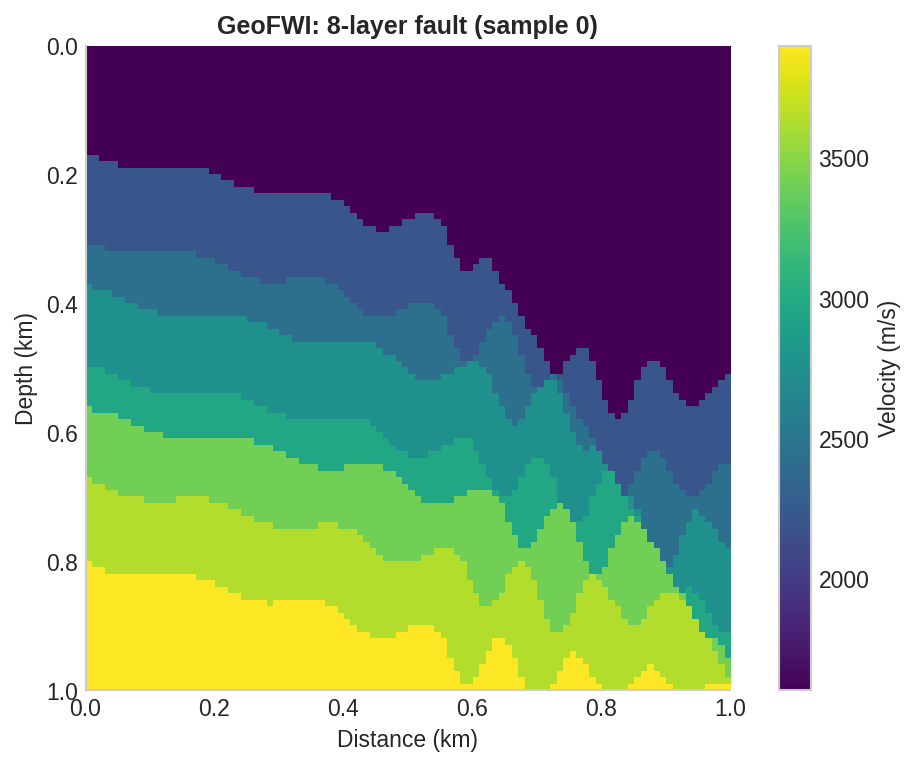

In [3]:
import geofwi
from time import perf_counter
LAYER = 8
MODE = 'fault'
MODEL_INDEX = 0  # index within this geological category
print('Preparing GeoFWI dataset...', flush=True)
t0 = perf_counter()
path = geofwi.download(progress=True)
print(f'Dataset location: {path}; elapsed: {perf_counter()-t0:.1f} s', flush=True)
arrays = geofwi.find_arrays(path)
files = [Path(p) for p in arrays if Path(p).name == 'geofwi.npy']
if len(files) != 1:
    raise RuntimeError(f'Expected one geofwi.npy; found {files}')
v_true_np = np.array(geofwi.get_vel(layer=LAYER, mode=MODE,
    datapath=str(files[0].parent), indx=MODEL_INDEX), dtype=np.float32, order='C', copy=True)
assert v_true_np.shape == (100, 100), v_true_np.shape
assert np.isfinite(v_true_np).all() and v_true_np.min() >= 500 and v_true_np.max() <= 10000
N = v_true_np.shape[0]
dx = 10.0
VMIN = min(1300., float(v_true_np.min()))
VMAX = max(4500., 1.25*float(v_true_np.max()))
dt = min(0.0015, 0.6*dx/VMAX)
nt = int(np.ceil(0.6/dt))
v_true = torch.tensor(v_true_np, device=device)
print(f'{LAYER}-layer {MODE} | native grid {N} × {N} | dt={dt:.6f} s | nt={nt}')
print(f'Velocity range: {v_true_np.min():.0f}–{v_true_np.max():.0f} m/s')
fig, ax = plt.subplots(figsize=(6,5), layout='constrained')
im = ax.imshow(v_true_np, cmap='viridis', extent=[0,N*dx/1000,N*dx/1000,0])
ax.set(title=f'GeoFWI: {LAYER}-layer {MODE} (sample {MODEL_INDEX})', xlabel='Distance (km)', ylabel='Depth (km)')
fig.colorbar(im, ax=ax, label='Velocity (m/s)')
plt.show()

## Shared numerical engine
The following implementation is deliberately explicit so that every operation is inspectable. Source amplitude is in arbitrary units; the discrete forcing already includes the time-step scaling convention.

In [4]:
# A differentiable second-order acoustic finite-difference solver.
# Array ordering: [shot, depth, horizontal]. All units are SI.
def ricker(f, t0=None):
    t=torch.arange(nt,device=device)*dt
    a=(torch.pi*f*(t-(1.5/f if t0 is None else t0)))**2
    return (1-2*a)*torch.exp(-a)
def forward(v, f=15., shots=(17,50,82), snapshots=False):
    assert float(v.detach().max())*dt/dx<1/np.sqrt(2), 'CFL violation'
    ns=len(shots); zsrc=10; zrec=10
    src=torch.zeros((ns,N,N),device=device)
    for i,x in enumerate(shots): src[i,zsrc,x]=1
    coords=torch.arange(N,device=device)
    # Sponge on all boundaries, not a free surface or PML.
    edge=torch.minimum(coords,N-1-coords).float()
    taper=torch.exp(-0.12*((10-edge).clamp(min=0)/10)**2)
    damp=taper[:,None]*taper[None,:]
    u=torch.zeros_like(src); old=torch.zeros_like(src)
    rec=[]; frames=[]; w=ricker(f); c=(v*dt/dx)**2
    for k in range(nt):
        p=torch.nn.functional.pad(u,(1,1,1,1))
        lap=p[:,2:,1:-1]+p[:,:-2,1:-1]+p[:,1:-1,2:]+p[:,1:-1,:-2]-4*u
        new=damp*(2*u-old+c*lap+src*w[k])
        old,u=u,new
        rec.append(u[:,zrec,10:-10])
        if snapshots and k in tuple(int(nt*f) for f in (.2,.4,.6,.8)): frames.append(u[0].detach().cpu().numpy())
    result=torch.stack(rec,dim=1)
    return (result,frames) if snapshots else result
def arr(x): return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
def modelplot(ax,v,title,limits=None):
    im=ax.imshow(arr(v),cmap='viridis',extent=[0,N*dx/1000,N*dx/1000,0],aspect='equal',**({} if limits is None else dict(vmin=limits[0],vmax=limits[1])))
    ax.set(xlabel='Distance (km)',ylabel='Depth (km)',title=title); plt.colorbar(im,ax=ax,label='m/s',shrink=.8)
def gather(ax,d,title,clip=None):
    a=arr(d); clip=np.percentile(np.abs(a),98) if clip is None else clip
    im=ax.imshow(a,aspect='auto',cmap='gray',vmin=-max(clip,1e-8),vmax=max(clip,1e-8),extent=[10*dx/1000,(N-11)*dx/1000,nt*dt,0]); ax.set(xlabel='Receiver x (km)',ylabel='Time (s)',title=title); plt.colorbar(im,ax=ax,shrink=.8,label='Amplitude (a.u.)')
def loss(pred,obs): return .5*(pred-obs).square().mean()/(obs.square().mean()+1e-12)
v0=torch.tensor(gaussian_filter(v_true_np,10),device=device)


## 1. Adjoint and chain rule
Write $A(v)p=s$, $r=Rp-d$. For $\Phi=\tfrac12 r^Tr$, solve $A^T\lambda=R^Tr$. Differentiating the wave equation gives
$$\delta\Phi=-\lambda^T(\delta A)p.$$
For $A=m\partial_t^2-\nabla^2$, $m=v^{-2}$ and model-independent forcing,
$$g_m=-\int\lambda p_{tt}\,dt,\qquad g_v=-2v^{-3}g_m.$$
The exact discrete gradient depends on the discretization and source convention. Our solver uses a velocity-independent forcing in the acceleration update; PyTorch differentiates that actual discrete recurrence, rather than assuming the above continuous source convention. Reverse-mode differentiation is the discrete adjoint of the implemented computational graph.


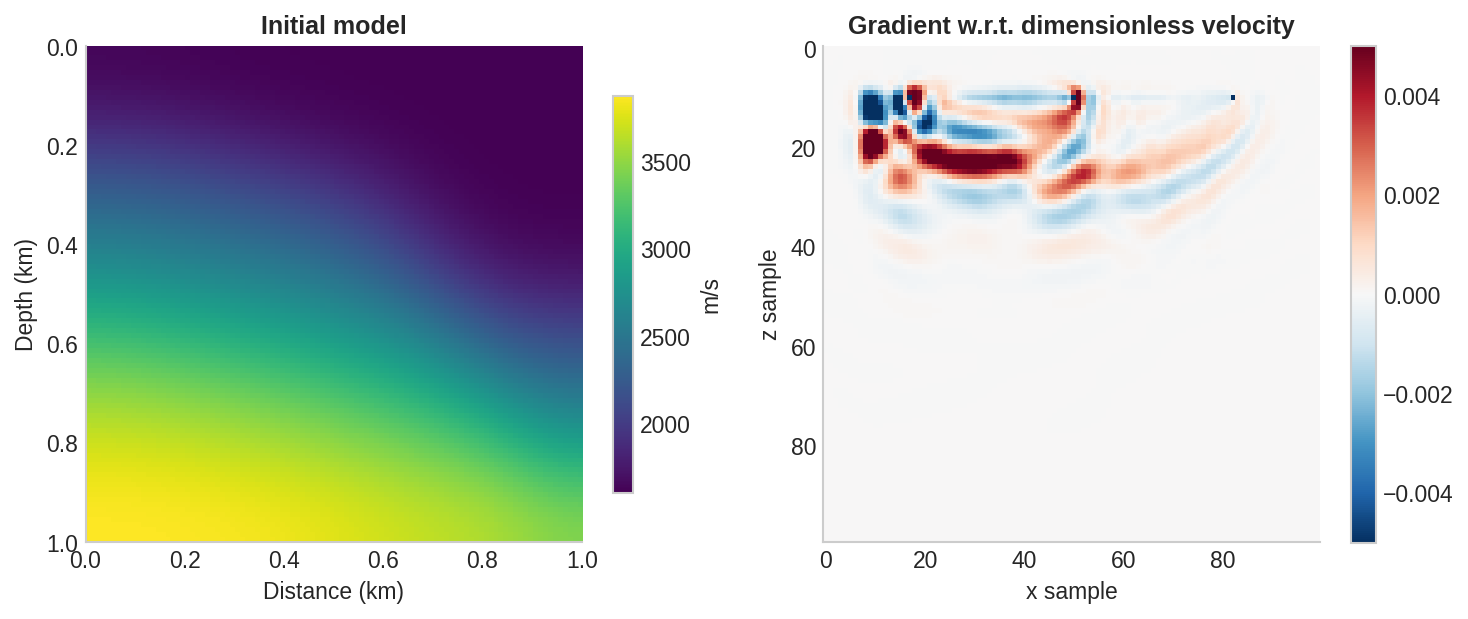

In [5]:
with torch.no_grad(): obs=forward(v_true)
q=(v0/2000).detach().requires_grad_(); J=loss(forward(2000*q),obs); J.backward(); g=q.grad.detach()
fig,ax=plt.subplots(1,2,figsize=(10,4)); modelplot(ax[0],v0,'Initial model'); lim=max(np.percentile(np.abs(arr(g)),99),1e-12); im=ax[1].imshow(arr(g),cmap='RdBu_r',vmin=-lim,vmax=lim); ax[1].set(title='Gradient w.r.t. dimensionless velocity',xlabel='x sample',ylabel='z sample'); fig.colorbar(im,ax=ax[1]); plt.tight_layout(); plt.show()

## 2. Taylor test
For a unit perturbation $h$, the linear prediction is $\Phi(q+\epsilon h)=\Phi(q)+\epsilon g^Th+O(\epsilon^2)$. The remainder should decrease quadratically until roundoff dominates. Use the normalized gradient direction to avoid a vanishing directional derivative.

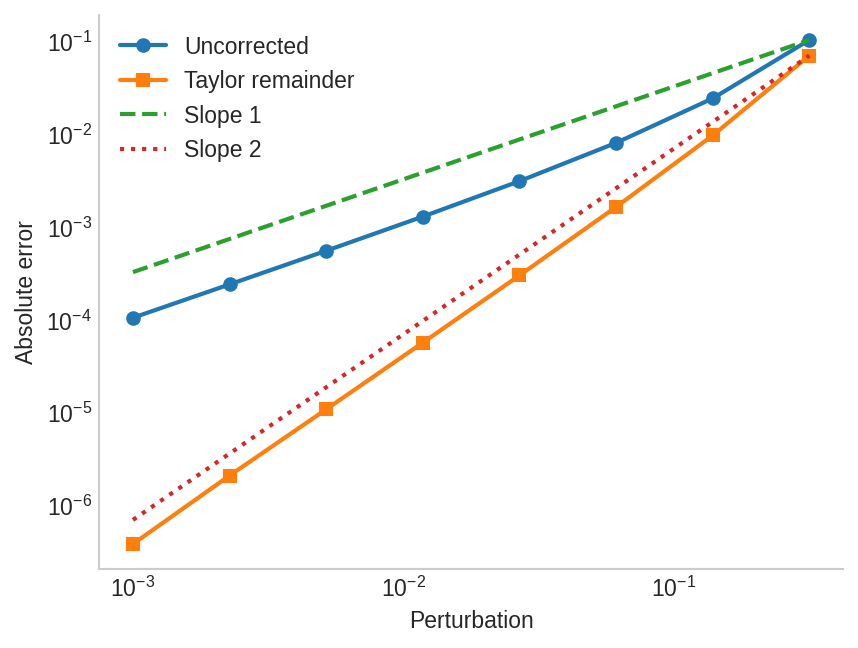

In [6]:
h=g/g.norm().clamp_min(1e-12); eps=np.logspace(-3,-.5,8); e0=[]; e1=[]
with torch.no_grad():
 for e in eps:
  diff=float(loss(forward(2000*(q+e*h)),obs)-J); e0.append(abs(diff)); e1.append(abs(diff-e*float((g*h).sum())))
plt.loglog(eps,e0,'o-',label='Uncorrected'); plt.loglog(eps,e1,'s-',label='Taylor remainder'); plt.loglog(eps,e0[-1]*eps/eps[-1],'--',label='Slope 1'); plt.loglog(eps,max(e1[-1],1e-12)*(eps/eps[-1])**2,':',label='Slope 2'); plt.xlabel('Perturbation'); plt.ylabel('Absolute error'); plt.legend(); plt.show()

## 3. Gradient descent and line search
A descent step is $q_{k+1}=q_k-\alpha g_k$. Scan several candidate step lengths. Too large a step may increase the objective; normalization makes the trial step interpretable.

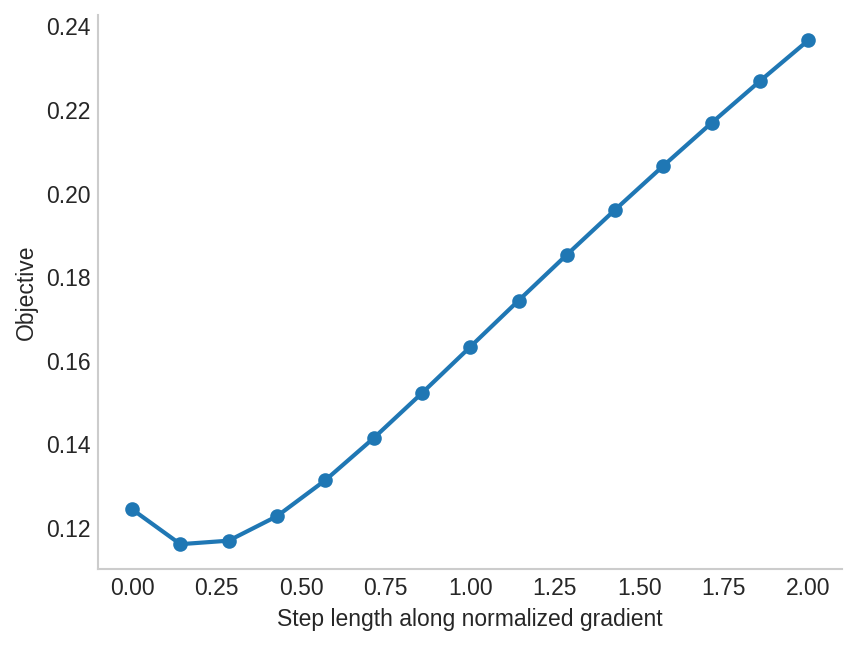

Best trial: 0.14285714285714285


In [7]:
alphas=np.linspace(0,2,15); values=[]
with torch.no_grad():
 for a in alphas: values.append(float(loss(forward(2000*(q-a*h).clamp(VMIN/2000,VMAX/2000)),obs)))
plt.plot(alphas,values,'o-'); plt.xlabel('Step length along normalized gradient'); plt.ylabel('Objective'); plt.show()
print('Best trial:',alphas[np.argmin(values)])

## 4. Exercises
Compare gradient illumination for one and three shots. Try a random Taylor direction. Explain why an adjoint test is not proof of physical accuracy.